# 01 · Data checks & main effects

**Business question:** Does sending a promotional e-mail make customers visit and buy more — and is the men's or the women's campaign more effective?

**Experiment:** 64,000 customers who bought in the last 12 months were randomly split into three equal groups: *Mens E-Mail*, *Womens E-Mail*, *No E-Mail* (control). Outcomes were tracked for two weeks.

**This notebook:**
1. Data-quality checks in SQL
2. Experiment health: sample ratio mismatch (SRM) and covariate balance
3. Main effects on visit and conversion, with Holm correction for two comparisons
4. Effect on spend with a bootstrap CI

In [10]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, stats_utils as su

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1 · Load data

In [2]:
csv_path = data.download()          # downloads once into data/, then reuses the file
df = data.load(csv_path)
print(df.shape)
df.head()

(64000, 12)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.4400,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0000
1,6,3) $200 - $350,329.0800,1,1,Rural,1,Web,No E-Mail,0,0,0.0000
2,7,2) $100 - $200,180.6500,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0000
3,9,5) $500 - $750,675.8300,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0000
4,2,1) $0 - $100,45.3400,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0000


## 2 · Data-quality checks (SQL)

All checks live in `sql/01_data_checks.sql` so they can be reviewed and rerun on their own.

In [3]:
con = data.to_sqlite(df)
queries = data.read_named_queries(ROOT / "sql" / "01_data_checks.sql")
sql_results = {name: pd.read_sql(q, con) for name, q in queries.items()}
for name in ["row_count", "missing_values", "logical_consistency"]:
    print(f"--- {name}")
    display(sql_results[name])

--- row_count


,n_rows
0,64000


--- missing_values


,recency_null,history_null,segment_null,visit_null,conversion_null,spend_null
0,0,0,0,0,0,0


--- logical_consistency


,conversion_without_visit,spend_without_conversion,conversion_with_zero_spend,negative_values
0,0,0,0,0


In [4]:
sql_results["outcomes_by_group"]

,segment,n_customers,visit_rate_pct,conversion_rate_pct,spend_per_customer,avg_order_value
0,Mens E-Mail,21307,18.2800,1.2500,1.4230,113.5300
1,No E-Mail,21306,10.6200,0.5700,0.6530,114.0000
2,Womens E-Mail,21387,15.1400,0.8800,1.0770,121.8900


## 3 · Experiment health

### 3a · Sample ratio mismatch
The design planned a 1/3 split. If the observed split deviates more than chance allows, the assignment (or the logging) is broken and every downstream result is suspect.

In [5]:
group_counts = df["segment"].value_counts().sort_index()
srm = su.srm_test(group_counts)
print(group_counts.to_string())
print(f"\nSRM chi2 = {srm['chi2']:.2f}, p = {srm['p_value']:.4f}",
      "-> OK" if srm["p_value"] > 0.001 else "-> WARNING: possible SRM")

segment
Mens E-Mail      21307
No E-Mail        21306
Womens E-Mail    21387

SRM chi2 = 0.20, p = 0.9037 -> OK


### 3b · Covariate balance
Pre-treatment characteristics should be similar across arms. Rule of thumb: |standardized mean difference| < 0.1.

In [6]:
model_df = df.assign(
    zip_urban=(df["zip_code"] == "Urban").astype(int),
    zip_rural=(df["zip_code"] == "Rural").astype(int),
    channel_web=(df["channel"] == "Web").astype(int),
    channel_phone=(df["channel"] == "Phone").astype(int),
)
covariates = ["recency", "history", "mens", "womens", "newbie",
              "zip_urban", "zip_rural", "channel_web", "channel_phone"]
balance = su.balance_table(model_df, "segment", data.CONTROL, covariates)
print("Max |SMD|:", round(balance["smd"].abs().max(), 4))
balance.pivot(index="covariate", columns="arm", values="smd")

Max |SMD|: 0.0137


arm,Mens E-Mail,Womens E-Mail
covariate,,
channel_phone,-0.0083,0.0086
channel_web,0.0110,-0.0051
history,0.0076,0.0065
mens,-0.0046,-0.0086
newbie,-0.0009,0.0026
recency,0.0068,0.0052
womens,0.0076,0.0049
zip_rural,0.0137,0.0040
zip_urban,0.0020,-0.0018


## 4 · Main effects: visit & conversion

Each e-mail arm is compared with the control group. Two arms × two metrics = four tests, so p-values are Holm-adjusted to keep the family-wise error rate at 5%.

In [7]:
ctrl = df[df["segment"] == data.CONTROL]
rows = []
for arm in data.TREATMENTS:
    treat = df[df["segment"] == arm]
    for metric in ["visit", "conversion"]:
        res = su.diff_in_proportions(treat[metric], ctrl[metric])
        rows.append({"arm": arm, "metric": metric, **res})

effects = pd.DataFrame(rows)
effects["p_holm"] = su.holm_adjust(effects["p_value"].tolist())
effects[["arm", "metric", "rate_control", "rate_treatment", "abs_lift",
         "ci_low", "ci_high", "rel_lift", "p_value", "p_holm"]]

,arm,metric,rate_control,rate_treatment,abs_lift,ci_low,ci_high,rel_lift,p_value,p_holm
0,Mens E-Mail,visit,0.1062,0.1828,0.0766,0.0700,0.0832,0.7214,0.0000,0.0000
1,Mens E-Mail,conversion,0.0057,0.0125,0.0068,0.0050,0.0086,1.1884,0.0000,0.0000
2,Womens E-Mail,visit,0.1062,0.1514,0.0452,0.0389,0.0516,0.4261,0.0000,0.0000
3,Womens E-Mail,conversion,0.0057,0.0088,0.0031,0.0015,0.0047,0.5433,0.0002,0.0002


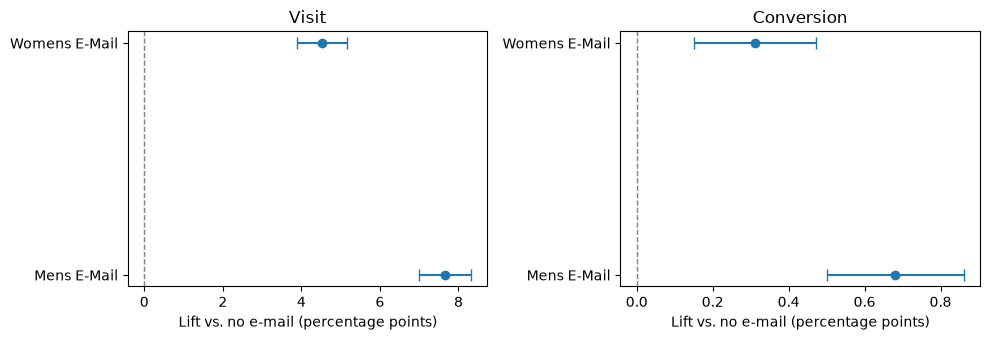

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, metric in zip(axes, ["visit", "conversion"]):
    sub = effects[effects["metric"] == metric]
    y = np.arange(len(sub))
    ax.errorbar(sub["abs_lift"] * 100, y,
                xerr=[(sub["abs_lift"] - sub["ci_low"]) * 100, (sub["ci_high"] - sub["abs_lift"]) * 100],
                fmt="o", capsize=4)
    ax.axvline(0, color="grey", lw=1, ls="--")
    ax.set_yticks(y, sub["arm"])
    ax.set_xlabel("Lift vs. no e-mail (percentage points)")
    ax.set_title(metric.capitalize())
plt.tight_layout()
plt.show()

## 5 · Spend per customer (bootstrap)

Spend is zero for >99% of customers and very skewed for the rest, so the CI comes from 5,000 bootstrap resamples rather than a normal approximation.

In [9]:
spend_rows = []
for arm in data.TREATMENTS:
    treat = df[df["segment"] == arm]
    spend_rows.append({"arm": arm, **su.bootstrap_mean_diff(treat["spend"], ctrl["spend"])})
spend_effects = pd.DataFrame(spend_rows)
spend_effects["p_holm"] = su.holm_adjust(spend_effects["p_value_boot"].tolist())
spend_effects

,arm,mean_treatment,mean_control,diff,ci_low,ci_high,p_value_boot,p_holm
0,Mens E-Mail,1.4226,0.6528,0.7698,0.4791,1.0492,0.0002,0.0004
1,Womens E-Mail,1.0772,0.6528,0.4244,0.1588,0.6844,0.0012,0.0012


## 6 · Interim findings

- **Health:** The three groups are balanced (SRM p = 0.90; max |SMD| = 0.014 < 0.1), so differences can be attributed to the e-mails.
- **Visit / conversion:** The men's e-mail raised the visit rate from 10.6% to 18.3% (+7.7 pp, 95% CI [7.0, 8.3]) and conversion from 0.57% to 1.25% (+0.68 pp, [0.50, 0.86]). The women's e-mail had smaller but still significant effects (visit +4.5 pp; conversion +0.31 pp, [0.15, 0.47]). All p < 0.001 after Holm correction.
- **Spend:** The men's e-mail added $0.77 per customer (95% CI [0.48, 1.05]), about **$770 incremental revenue per 1,000 e-mails**, versus $0.42 ([0.16, 0.68]) for the women's e-mail.
- **Caveat:** Conversions are rare (~0.6% in control), so conversion and spend estimates are much less precise than visit estimates.

**Next notebook (02):** CUPED variance reduction with past-year spend, power / minimum detectable effect, and segment-level (heterogeneous) effects.